# Экспериментальное исследование влияния параметров алгоритмов хранения паролей на вычислительные затраты

## Импорт библиотек

In [48]:
import time
import sys
import hashlib
import warnings
import platform
import ast
import hmac
from pathlib import Path

import bcrypt
import psutil
from argon2 import PasswordHasher
from argon2.low_level import hash_secret_raw, Type
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

In [49]:
warnings.filterwarnings('ignore')

%matplotlib inline 

plt.style.use('ggplot')
plt.rcParams['figure.figsize'] = (10, 6)
plt.rcParams['font.size'] = 12

Path('results').mkdir(exist_ok=True)
Path('figures').mkdir(exist_ok=True)

In [50]:
passwords = []

with open("input_data/passwords.txt", 'r', encoding='utf-8') as f:
    for pwd in f:
        pwd = pwd.rstrip('\r\n')

        if pwd.startswith(("b'", 'b"')):
            pwd = ast.literal_eval(pwd).decode('utf-8')

        if pwd:
            passwords.append(pwd)

print(f"Загружено паролей: {len(passwords)}")

Загружено паролей: 1000


## Характеристики экспериментальной среды

In [51]:
system_info = {
    'Операционная система': platform.platform(),
    'Процессор': platform.processor(),
    'Логических процессоров': psutil.cpu_count(logical=True),
    'Оперативная память (ГиБ)': round(psutil.virtual_memory().total / 1024**3, 2),
    'Версия Python': sys.version.split()[0],
    'Количество паролей': len(passwords)
}

for key, value in system_info.items():
    print(f'{key}: {value}')

with open('results/system_info.txt', 'w', encoding='utf-8') as f:
    for key, value in system_info.items():
        f.write(f'{key}: {value}\n')

Операционная система: Windows-11-10.0.26200-SP0
Процессор: AMD64 Family 25 Model 97 Stepping 2, AuthenticAMD
Логических процессоров: 12
Оперативная память (ГиБ): 31.09
Версия Python: 3.14.0
Количество паролей: 1000


## Функция замера времени

In [52]:
def measure_time(func, *args, **kwargs):
    start_time = time.perf_counter()
    result = func(*args, **kwargs)
    end_time = time.perf_counter()

    time_ms = (end_time - start_time) * 1000

    return result, time_ms

## Эксперимент

### Bcrypt

In [53]:
def hash_bcrypt(password, cost_factor):
    salt = bcrypt.gensalt(rounds=cost_factor)
    return bcrypt.hashpw(password.encode('utf-8'), salt)

In [54]:
def run_bcrypt_experiment(passwords, cost_factors, repeats=100):
    results = []

    for cost in cost_factors:
        print(f"Тестируем bcrypt с cost={cost}...")

        times = []

        # Прогрев
        hash_bcrypt(passwords[0], cost)

        for i in range(repeats):
            pwd = passwords[i % len(passwords)]

            res, time_res = measure_time(hash_bcrypt, pwd, cost)

            times.append(time_res)

        results.append({
            'algorithm': 'bcrypt',
            'parameter_name': 'cost_factor',
            'parameter_value': cost,
            'time_ms': round(np.median(times), 3),
            'std_ms': round(np.std(times, ddof=1), 3) if repeats > 1 else 0,
            'q1_ms': round(np.percentile(times, 25), 3),
            'q3_ms': round(np.percentile(times, 75), 3),
            'times': times
        })

    return results

In [55]:
cost_factors_to_test = [4, 6, 8, 10, 12]

bcrypt_results = run_bcrypt_experiment(passwords, cost_factors_to_test, repeats=100)

df_bcrypt = pd.DataFrame(bcrypt_results)
df_bcrypt.drop(columns=['times']).to_csv('results/bcrypt_results.csv', index=False)

df_bcrypt.drop(columns=['times'])

Тестируем bcrypt с cost=4...
Тестируем bcrypt с cost=6...
Тестируем bcrypt с cost=8...
Тестируем bcrypt с cost=10...
Тестируем bcrypt с cost=12...


,algorithm,parameter_name,parameter_value,time_ms,std_ms,q1_ms,q3_ms
0,bcrypt,cost_factor,4,0.784,0.117,0.754,0.798
1,bcrypt,cost_factor,6,2.900,0.136,2.892,2.917
2,bcrypt,cost_factor,8,10.577,0.310,10.490,10.888
3,bcrypt,cost_factor,10,41.986,0.926,41.829,42.742
4,bcrypt,cost_factor,12,167.843,2.629,167.468,169.919


In [56]:
df_bcrypt = pd.DataFrame(bcrypt_results)
df_bcrypt.drop(columns=['times']).to_csv('results/bcrypt_results.csv', index=False)
df_bcrypt.drop(columns=['times'])

,algorithm,parameter_name,parameter_value,time_ms,std_ms,q1_ms,q3_ms
0,bcrypt,cost_factor,4,0.784,0.117,0.754,0.798
1,bcrypt,cost_factor,6,2.900,0.136,2.892,2.917
2,bcrypt,cost_factor,8,10.577,0.310,10.490,10.888
3,bcrypt,cost_factor,10,41.986,0.926,41.829,42.742
4,bcrypt,cost_factor,12,167.843,2.629,167.468,169.919


### Argon2: влияние memory_cost

In [57]:
def hash_argon2(password, memory_cost, time_cost=3):
    ph = PasswordHasher(time_cost=time_cost, memory_cost=memory_cost, parallelism=4, type=Type.ID)
    return ph.hash(password)

In [58]:
def run_argon2_experiment(passwords, memory_costs, repeats=100, time_cost=3):
    results = []

    for mem_cost in memory_costs:
        print(f"Тестируем Argon2id с memory_cost={mem_cost} КиБ...")

        times = []

        hash_argon2(passwords[0], mem_cost, time_cost)

        for i in range(repeats):
            pwd = passwords[i % len(passwords)]

            res, time_res = measure_time(hash_argon2, pwd, mem_cost, time_cost)

            times.append(time_res)

        results.append({
            'algorithm': 'Argon2id',
            'parameter_name': 'memory_cost_kib',
            'parameter_value': mem_cost,
            'time_ms': round(np.median(times), 3),
            'std_ms': round(np.std(times, ddof=1), 3) if repeats > 1 else 0,
            'q1_ms': round(np.percentile(times, 25), 3),
            'q3_ms': round(np.percentile(times, 75), 3),
            'memory_cost_mib': mem_cost / 1024,
            'times': times
        })

    return results

In [59]:
memory_costs_to_test = [16384, 32768, 65536, 131072] # 16 МБ, 32 МБ, 64 МБ и 128 МБ соответсвенно
argon2_results = run_argon2_experiment(passwords, memory_costs_to_test, repeats=100)

df_argon2 = pd.DataFrame(argon2_results)
df_argon2.drop(columns=['times']).to_csv('results/argon2_results.csv', index=False)

df_argon2.drop(columns=['times'])

Тестируем Argon2id с memory_cost=16384 КиБ...
Тестируем Argon2id с memory_cost=32768 КиБ...
Тестируем Argon2id с memory_cost=65536 КиБ...
Тестируем Argon2id с memory_cost=131072 КиБ...


,algorithm,parameter_name,parameter_value,time_ms,std_ms,q1_ms,q3_ms,memory_cost_mib
0,Argon2id,memory_cost_kib,16384,9.694,1.285,9.328,9.999,16.0
1,Argon2id,memory_cost_kib,32768,17.958,0.482,17.639,18.215,32.0
2,Argon2id,memory_cost_kib,65536,36.060,1.157,35.606,36.478,64.0
3,Argon2id,memory_cost_kib,131072,72.607,2.025,71.931,73.385,128.0


### PBKDF2

In [60]:
def hash_pbkdf2(password, iterations):
    salt = b'some_fixed_salt_123'
    return hashlib.pbkdf2_hmac('sha256', password.encode('utf-8'), salt, iterations)

In [61]:
def run_pbkdf2_experiment(passwords, iterations_list, repeats=100):
    results = []

    for iters in iterations_list:
        print(f"Тестируем PBKDF2 с iterations={iters}...")

        times = []

        hash_pbkdf2(passwords[0], iters)

        for i in range(repeats):
            pwd = passwords[i % len(passwords)]

            res, time_res = measure_time(hash_pbkdf2, pwd, iters)

            times.append(time_res)

        results.append({
            'algorithm': 'PBKDF2',
            'parameter_name': 'iterations',
            'parameter_value': iters,
            'time_ms': round(np.median(times), 3),
            'std_ms': round(np.std(times, ddof=1), 3) if repeats > 1 else 0,
            'q1_ms': round(np.percentile(times, 25), 3),
            'q3_ms': round(np.percentile(times, 75), 3),
            'times': times
        })

    return results

In [62]:
iterations_to_test = [10000, 50000, 100000, 200000, 500000]
pbkdf2_results = run_pbkdf2_experiment(passwords, iterations_to_test, repeats=100)

df_pbkdf2 = pd.DataFrame(pbkdf2_results)
df_pbkdf2.drop(columns=['times']).to_csv('results/pbkdf2_results.csv', index=False)
df_pbkdf2.drop(columns=['times'])
df_pbkdf2

Тестируем PBKDF2 с iterations=10000...
Тестируем PBKDF2 с iterations=50000...
Тестируем PBKDF2 с iterations=100000...
Тестируем PBKDF2 с iterations=200000...
Тестируем PBKDF2 с iterations=500000...


,algorithm,parameter_name,parameter_value,time_ms,std_ms,q1_ms,q3_ms,times
0,PBKDF2,iterations,10000,2.601,0.684,2.582,2.888,"[4.503700009081513, 3.922700008843094, 3.15750..."
1,PBKDF2,iterations,50000,13.182,0.513,13.052,13.277,"[12.931699995533563, 15.178000001469627, 13.36..."
2,PBKDF2,iterations,100000,26.403,1.173,26.198,27.299,"[27.87989999342244, 27.73269999306649, 28.6411..."
3,PBKDF2,iterations,200000,53.621,2.783,52.506,54.743,"[53.37090000102762, 52.89910000283271, 53.0087..."
4,PBKDF2,iterations,500000,131.999,4.612,130.634,135.187,"[132.01180000032764, 131.14510000741575, 132.1..."


### Argon2id: влияние time_cost

In [63]:
def run_argon2_time_experiment(passwords, time_costs, repeats=100):
    results = []

    memory_cost = 65536  # 64 МиБ

    for time_cost in time_costs:
        print(f"Тестируем Argon2id с time_cost={time_cost}...")

        times = []

        hash_argon2(passwords[0], memory_cost, time_cost)

        for i in range(repeats):
            pwd = passwords[i % len(passwords)]

            res, time_res = measure_time(hash_argon2, pwd, memory_cost, time_cost)

            times.append(time_res)

        results.append({
            'algorithm': 'Argon2id',
            'parameter_name': 'time_cost',
            'parameter_value': time_cost,
            'time_ms': round(np.median(times), 3),
            'std_ms': round(np.std(times, ddof=1), 3) if repeats > 1 else 0,
            'q1_ms': round(np.percentile(times, 25), 3),
            'q3_ms': round(np.percentile(times, 75), 3),
            'times': times
        })

    return results

In [64]:
time_costs_to_test = [1, 2, 3, 4, 5]

argon2_time_results = run_argon2_time_experiment(passwords, time_costs_to_test, repeats=100)

df_argon2_time = pd.DataFrame(argon2_time_results)
df_argon2_time.drop(columns=['times']).to_csv('results/argon2_time_results.csv', index=False)

df_argon2_time.drop(columns=['times'])

Тестируем Argon2id с time_cost=1...
Тестируем Argon2id с time_cost=2...
Тестируем Argon2id с time_cost=3...
Тестируем Argon2id с time_cost=4...
Тестируем Argon2id с time_cost=5...


,algorithm,parameter_name,parameter_value,time_ms,std_ms,q1_ms,q3_ms
0,Argon2id,time_cost,1,14.743,1.177,14.483,15.043
1,Argon2id,time_cost,2,25.388,0.495,25.086,25.763
2,Argon2id,time_cost,3,35.956,0.586,35.703,36.338
3,Argon2id,time_cost,4,46.689,1.038,46.105,47.311
4,Argon2id,time_cost,5,57.145,1.557,56.610,57.784


## Исследование времени проверки паролей

In [65]:
def verify_password(password, stored_hash, algorithm):
    if algorithm == 'bcrypt':
        return bcrypt.checkpw(password.encode('utf-8'), stored_hash)

    if algorithm == 'Argon2id':
        ph = PasswordHasher()
        return ph.verify(stored_hash, password)

    if algorithm == 'PBKDF2':
        new_hash = hash_pbkdf2(password, 500000)
        return hmac.compare_digest(new_hash, stored_hash)

In [66]:
password = passwords[0]

hashes = {
    'bcrypt': hash_bcrypt(password, 12),
    'Argon2id': hash_argon2(password, 65536, 3),
    'PBKDF2': hash_pbkdf2(password, 500000)
}

verification_results = []

for algorithm, stored_hash in hashes.items():
    print(f"Тестируем проверку пароля: {algorithm}...")

    times = []

    # Проверка корректности
    assert verify_password(password, stored_hash, algorithm)

    # Проверка неверного пароля для bcrypt и PBKDF2
    if algorithm != 'Argon2id':
        assert not verify_password(password + '_wrong', stored_hash, algorithm)

    verify_password(password, stored_hash, algorithm)

    for i in range(30):
        res, time_res = measure_time(verify_password, password, stored_hash, algorithm)

        assert res
        times.append(time_res)

    verification_results.append({
        'algorithm': algorithm,
        'time_ms': round(np.median(times), 3),
        'std_ms': round(np.std(times, ddof=1), 3),
        'q1_ms': round(np.percentile(times, 25), 3),
        'q3_ms': round(np.percentile(times, 75), 3)
    })

df_verification = pd.DataFrame(verification_results)
df_verification.to_csv('results/verification_results.csv', index=False)

df_verification

Тестируем проверку пароля: bcrypt...
Тестируем проверку пароля: Argon2id...
Тестируем проверку пароля: PBKDF2...


,algorithm,time_ms,std_ms,q1_ms,q3_ms
0,bcrypt,167.386,1.004,167.322,167.847
1,Argon2id,36.132,3.356,35.859,36.690
2,PBKDF2,154.271,14.800,140.148,163.697


## Вывод результатов

In [67]:
all_results = (bcrypt_results + pbkdf2_results + argon2_results + argon2_time_results)

raw_results = []

for result in all_results:
    for i, time_ms in enumerate(result['times']):
        raw_results.append({
            'algorithm': result['algorithm'],
            'parameter_name': result['parameter_name'],
            'parameter_value': result['parameter_value'],
            'repeat': i + 1,
            'time_ms': time_ms
        })

df_raw = pd.DataFrame(raw_results)
df_raw.to_csv('results/raw_results.csv', index=False)

print(f"Сохранено {len(df_raw)} измерений.")

Сохранено 1900 измерений.


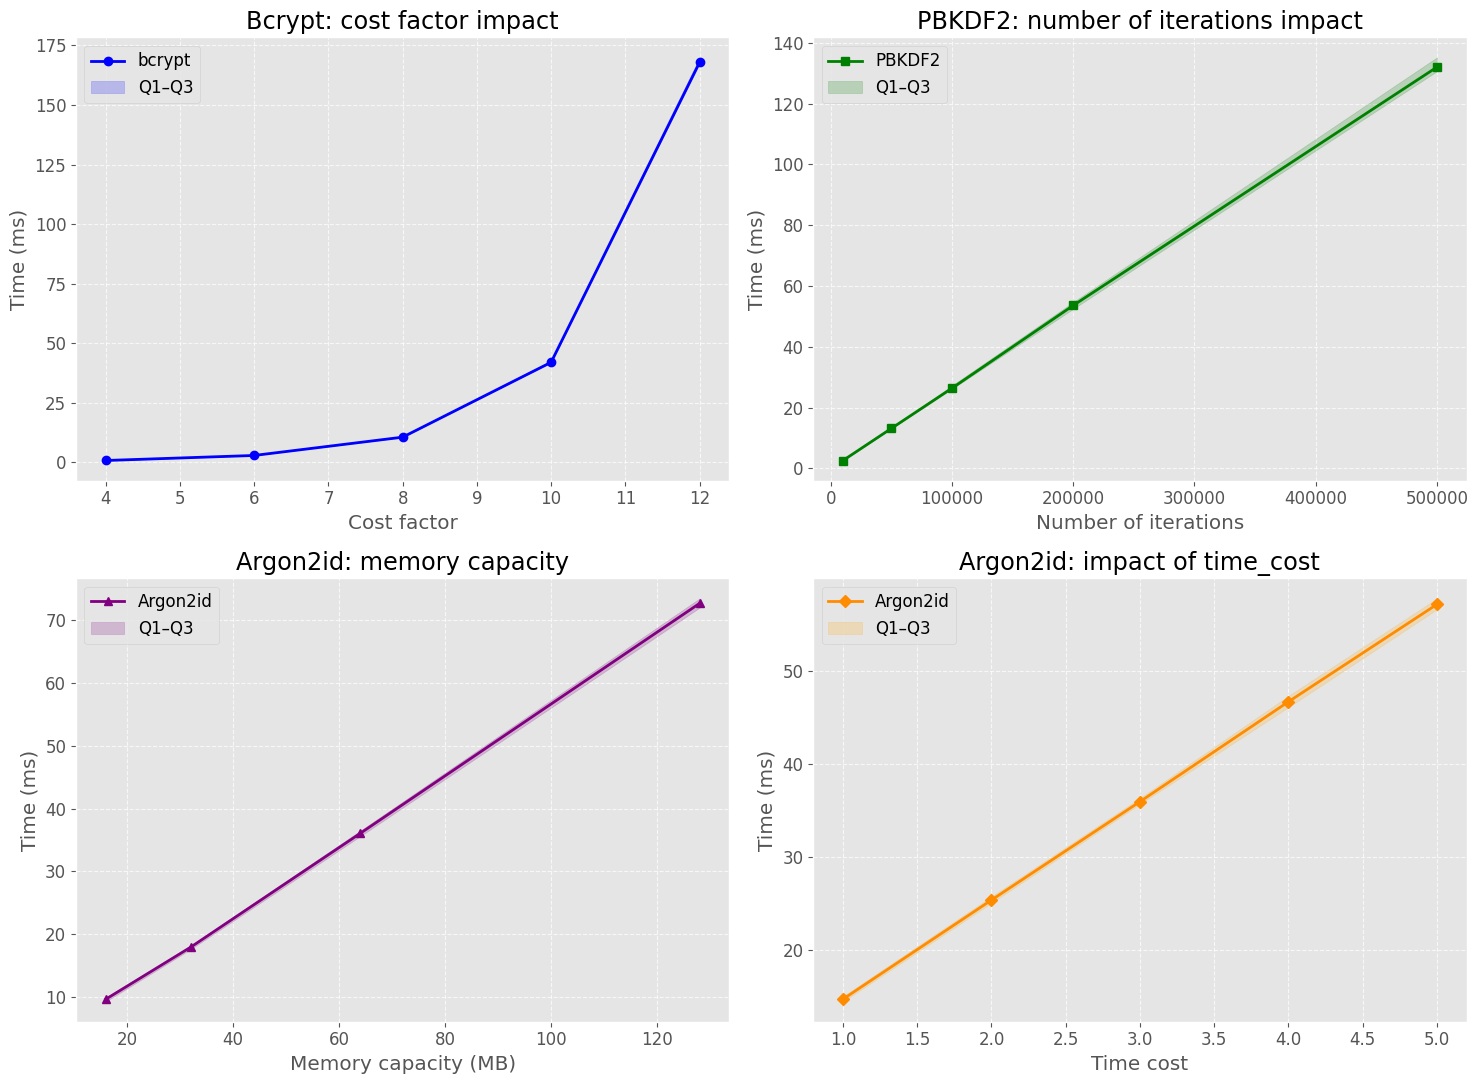

In [68]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Bcrypt
ax1 = axes[0, 0]

ax1.plot(df_bcrypt['parameter_value'], df_bcrypt['time_ms'],
         marker='o', linewidth=2, color='blue', label='bcrypt')

ax1.fill_between(df_bcrypt['parameter_value'],
                 df_bcrypt['q1_ms'], df_bcrypt['q3_ms'],
                 color='blue', alpha=0.2, label='Q1–Q3')

ax1.set_title('Bcrypt: cost factor impact')
ax1.set_xlabel('Cost factor')
ax1.set_ylabel('Time (ms)')
ax1.legend()


# PBKDF2
ax2 = axes[0, 1]

ax2.plot(df_pbkdf2['parameter_value'], df_pbkdf2['time_ms'],
         marker='s', linewidth=2, color='green', label='PBKDF2')

ax2.fill_between(df_pbkdf2['parameter_value'],
                 df_pbkdf2['q1_ms'], df_pbkdf2['q3_ms'],
                 color='green', alpha=0.2, label='Q1–Q3')

ax2.set_title('PBKDF2: number of iterations impact')
ax2.set_xlabel('Number of iterations')
ax2.set_ylabel('Time (ms)')
ax2.legend()


# Argon2id: память
ax3 = axes[1, 0]

ax3.plot(df_argon2['memory_cost_mib'], df_argon2['time_ms'],
         marker='^', linewidth=2, color='purple', label='Argon2id')

ax3.fill_between(df_argon2['memory_cost_mib'],
                 df_argon2['q1_ms'], df_argon2['q3_ms'],
                 color='purple', alpha=0.2, label='Q1–Q3')

ax3.set_title('Argon2id: memory capacity')
ax3.set_xlabel('Memory capacity (MB)')
ax3.set_ylabel('Time (ms)')
ax3.legend()


# Argon2id: time_cost
ax4 = axes[1, 1]

ax4.plot(df_argon2_time['parameter_value'], df_argon2_time['time_ms'],
         marker='D', linewidth=2, color='darkorange', label='Argon2id')

ax4.fill_between(df_argon2_time['parameter_value'],
                 df_argon2_time['q1_ms'], df_argon2_time['q3_ms'],
                 color='orange', alpha=0.2, label='Q1–Q3')

ax4.set_title('Argon2id: impact of time_cost')
ax4.set_xlabel('Time cost')
ax4.set_ylabel('Time (ms)')
ax4.legend()


for ax in axes.flat:
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('figures/parameter_plots_eng.png', dpi=300)
plt.show()

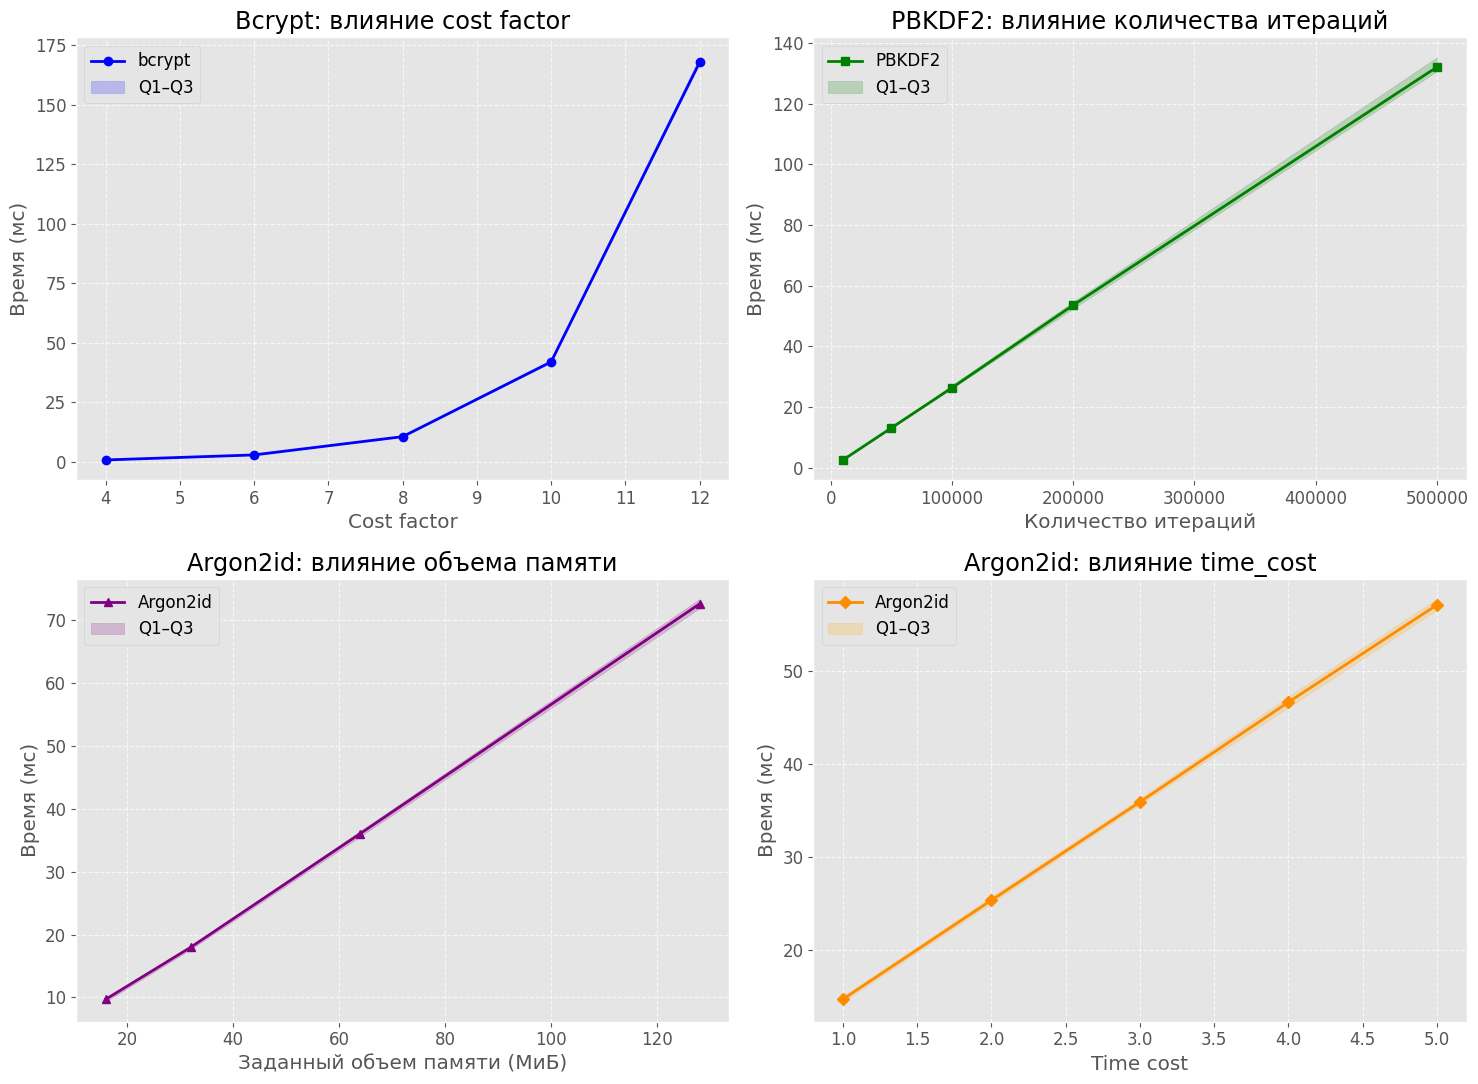

In [69]:
fig, axes = plt.subplots(2, 2, figsize=(15, 11))

# Bcrypt
ax1 = axes[0, 0]

ax1.plot(df_bcrypt['parameter_value'], df_bcrypt['time_ms'],
         marker='o', linewidth=2, color='blue', label='bcrypt')

ax1.fill_between(df_bcrypt['parameter_value'],
                 df_bcrypt['q1_ms'], df_bcrypt['q3_ms'],
                 color='blue', alpha=0.2, label='Q1–Q3')

ax1.set_title('Bcrypt: влияние cost factor')
ax1.set_xlabel('Cost factor')
ax1.set_ylabel('Время (мс)')
ax1.legend()


# PBKDF2
ax2 = axes[0, 1]

ax2.plot(df_pbkdf2['parameter_value'], df_pbkdf2['time_ms'],
         marker='s', linewidth=2, color='green', label='PBKDF2')

ax2.fill_between(df_pbkdf2['parameter_value'],
                 df_pbkdf2['q1_ms'], df_pbkdf2['q3_ms'],
                 color='green', alpha=0.2, label='Q1–Q3')

ax2.set_title('PBKDF2: влияние количества итераций')
ax2.set_xlabel('Количество итераций')
ax2.set_ylabel('Время (мс)')
ax2.legend()


# Argon2id: память
ax3 = axes[1, 0]

ax3.plot(df_argon2['memory_cost_mib'], df_argon2['time_ms'],
         marker='^', linewidth=2, color='purple', label='Argon2id')

ax3.fill_between(df_argon2['memory_cost_mib'],
                 df_argon2['q1_ms'], df_argon2['q3_ms'],
                 color='purple', alpha=0.2, label='Q1–Q3')

ax3.set_title('Argon2id: влияние объема памяти')
ax3.set_xlabel('Заданный объем памяти (МиБ)')
ax3.set_ylabel('Время (мс)')
ax3.legend()


# Argon2id: time_cost
ax4 = axes[1, 1]

ax4.plot(df_argon2_time['parameter_value'], df_argon2_time['time_ms'],
         marker='D', linewidth=2, color='darkorange', label='Argon2id')

ax4.fill_between(df_argon2_time['parameter_value'],
                 df_argon2_time['q1_ms'], df_argon2_time['q3_ms'],
                 color='orange', alpha=0.2, label='Q1–Q3')

ax4.set_title('Argon2id: влияние time_cost')
ax4.set_xlabel('Time cost')
ax4.set_ylabel('Время (мс)')
ax4.legend()


for ax in axes.flat:
    ax.grid(True, linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('figures/parameter_plots.png', dpi=300)
plt.show()

In [70]:
comparison_results = [
    {
        'algorithm': 'bcrypt',
        'hash_time_ms': df_bcrypt[df_bcrypt['parameter_value'] == 12]['time_ms'].iloc[0]
    },
    {
        'algorithm': 'PBKDF2',
        'hash_time_ms': df_pbkdf2[df_pbkdf2['parameter_value'] == 500000]['time_ms'].iloc[0]
    },
    {
        'algorithm': 'Argon2id',
        'hash_time_ms': df_argon2[df_argon2['parameter_value'] == 65536]['time_ms'].iloc[0]
    }
]

df_comparison = pd.DataFrame(comparison_results)

df_comparison = df_comparison.merge(df_verification[['algorithm', 'time_ms']], on='algorithm')

df_comparison = df_comparison.rename(columns={'time_ms': 'verify_time_ms'})

df_comparison.to_csv('results/comparison_results.csv', index=False)

df_comparison

,algorithm,hash_time_ms,verify_time_ms
0,bcrypt,167.843,167.386
1,PBKDF2,131.999,154.271
2,Argon2id,36.060,36.132


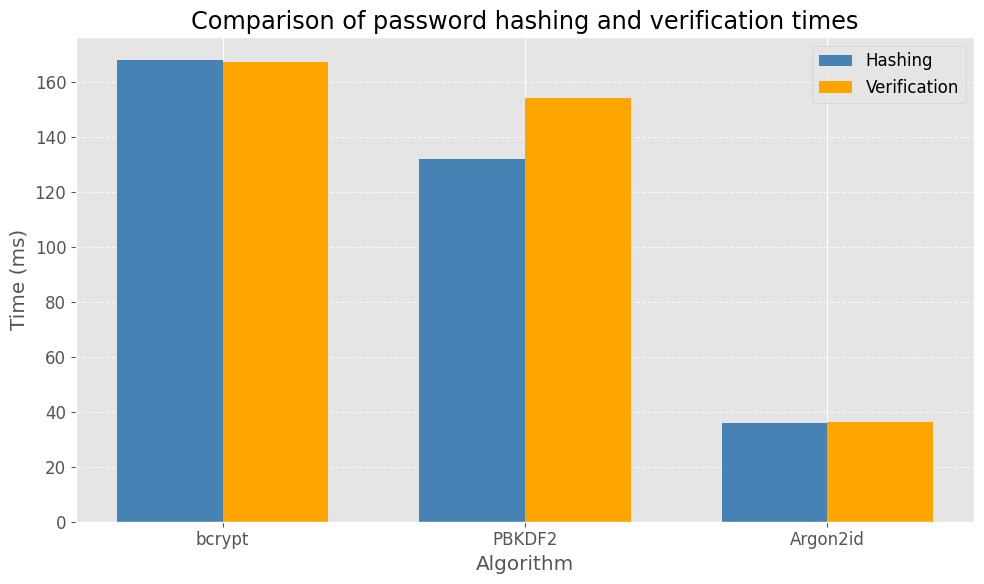

In [71]:
x = np.arange(len(df_comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(x - width / 2, df_comparison['hash_time_ms'],
       width, color='steelblue', label='Hashing')

ax.bar(x + width / 2, df_comparison['verify_time_ms'],
       width, color='orange', label='Verification')

ax.set_title('Comparison of password hashing and verification times')
ax.set_xlabel('Algorithm')
ax.set_ylabel('Time (ms)')
ax.set_xticks(x)
ax.set_xticklabels(df_comparison['algorithm'])
ax.legend()
ax.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('figures/hash_vs_verify_eng.png', dpi=300)
plt.show()

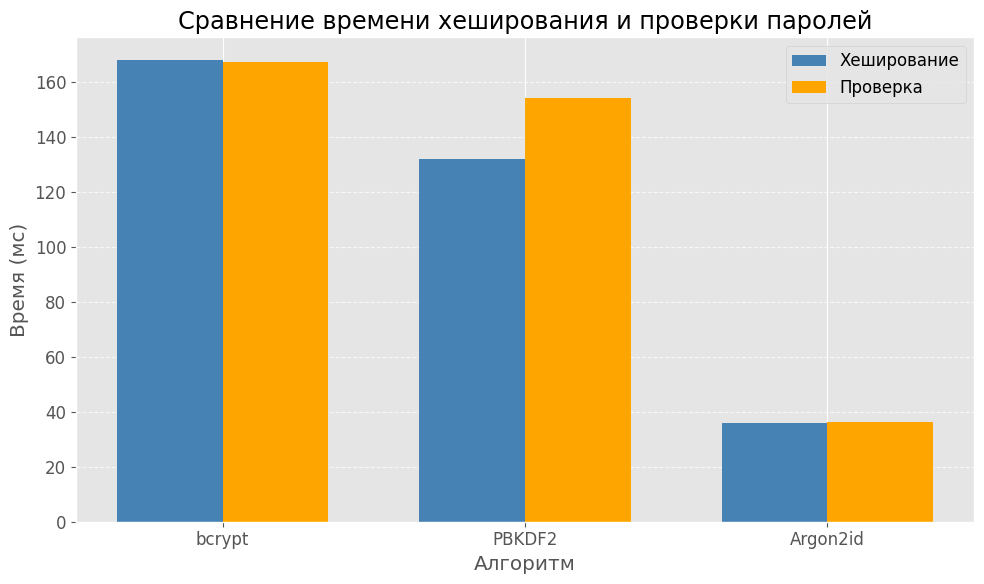

In [72]:
x = np.arange(len(df_comparison))
width = 0.35

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(x - width / 2, df_comparison['hash_time_ms'],
       width, color='steelblue', label='Хеширование')

ax.bar(x + width / 2, df_comparison['verify_time_ms'],
       width, color='orange', label='Проверка')

ax.set_title('Сравнение времени хеширования и проверки паролей')
ax.set_xlabel('Алгоритм')
ax.set_ylabel('Время (мс)')
ax.set_xticks(x)
ax.set_xticklabels(df_comparison['algorithm'])
ax.legend()
ax.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('figures/hash_vs_verify.png', dpi=300)
plt.show()

### Анализ разброса результатов

In [73]:
df_statistics = pd.concat([df_bcrypt, df_pbkdf2, df_argon2, df_argon2_time], ignore_index=True)

df_statistics['mean_ms'] = [np.mean(result['times']) for result in all_results]

df_statistics['cv_percent'] = (df_statistics['std_ms'] / df_statistics['mean_ms'] * 100).round(2)

df_statistics = df_statistics.drop(columns=['times'])

df_statistics.to_csv('results/statistics_results.csv', index=False)

df_statistics[['algorithm', 'parameter_name', 'parameter_value','time_ms', 'std_ms', 'cv_percent']]

,algorithm,parameter_name,parameter_value,time_ms,std_ms,cv_percent
0,bcrypt,cost_factor,4,0.784,0.117,14.47
1,bcrypt,cost_factor,6,2.900,0.136,4.70
2,bcrypt,cost_factor,8,10.577,0.310,2.89
3,bcrypt,cost_factor,10,41.986,0.926,2.18
4,bcrypt,cost_factor,12,167.843,2.629,1.55
5,PBKDF2,iterations,10000,2.601,0.684,23.42
6,PBKDF2,iterations,50000,13.182,0.513,3.86
7,PBKDF2,iterations,100000,26.403,1.173,4.36
8,PBKDF2,iterations,200000,53.621,2.783,5.13
9,PBKDF2,iterations,500000,131.999,4.612,3.44


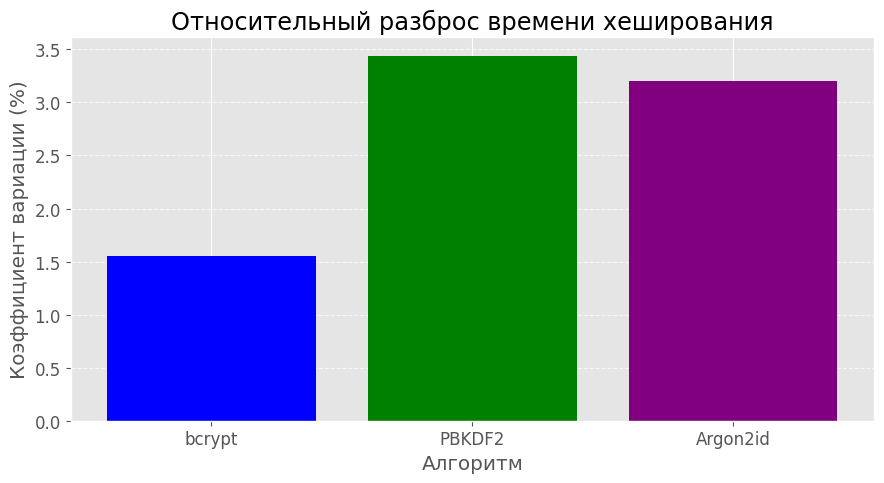

In [74]:
selected = df_statistics[
    ((df_statistics['algorithm'] == 'bcrypt') &
     (df_statistics['parameter_value'] == 12)) |

    ((df_statistics['algorithm'] == 'PBKDF2') &
     (df_statistics['parameter_value'] == 500000)) |

    ((df_statistics['parameter_name'] == 'memory_cost_kib') &
     (df_statistics['parameter_value'] == 65536))
].copy()

fig, ax = plt.subplots(figsize=(9, 5))

ax.bar(selected['algorithm'], selected['cv_percent'],
       color=['blue', 'green', 'purple'])

ax.set_title('Относительный разброс времени хеширования')
ax.set_xlabel('Алгоритм')
ax.set_ylabel('Коэффициент вариации (%)')
ax.grid(True, axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.savefig('figures/time_variation.png', dpi=300)
plt.show()

## Оценка применимости конфигураций

In [75]:
time_limit = 250  # мс

df_comparison['within_limit'] = ((df_comparison['hash_time_ms'] <= time_limit) & (df_comparison['verify_time_ms'] <= time_limit))

df_comparison['status'] = df_comparison['within_limit'].map({True: 'Соответствует', False: 'Не соответствует'})

df_comparison.to_csv('results/comparison_results.csv', index=False)

print(f'Выбранный порог времени: {time_limit} мс')

df_comparison

Выбранный порог времени: 250 мс


,algorithm,hash_time_ms,verify_time_ms,within_limit,status
0,bcrypt,167.843,167.386,True,Соответствует
1,PBKDF2,131.999,154.271,True,Соответствует
2,Argon2id,36.060,36.132,True,Соответствует
